# Beirut port explosion (4 August 2020): mapping building damage with Sentinel-2

Ines Hijazi 

**Use case:** after the explosion of 4 August 2020, rescue teams and NGOs need a quick first map of the damaged area.

**Question:** can free Sentinel-2 images, available a few days after the event, provide this map? What are their limits?

## 1. Parameters

In [41]:
# Bounding box found with http://bboxfinder.com/
# [lon_min, lat_min, lon_max, lat_max] in WGS84
aoi_bbox = [35.500, 33.885, 35.540, 33.910]
event_point = (33.9013, 35.5192)
event_name = "Beirut port explosion"
event_date = "2020-08-04"

#search windows before and after the event
start_date_BEFORE = "2020-07-15"
end_date_BEFORE   = "2020-08-03"
start_date_AFTER  = "2020-08-05"
end_date_AFTER    = "2020-08-25"

#max cloud cover (%): on the whole tile, then on our area
max_cloud_cover = 30
max_area_cloud = 5

resolution = 10 

# remove the pixels flagged as cloud by Sentinel-2
use_cloud_mask = True

# BDI thresholds
threshold_moderate = 2.0
threshold_severe   = 3.5

# Water if B08 (NIR) and B11 (SWIR) are both below this reflectance
water_threshold = 0.1

# Groups of changed pixels smaller than this are removed (noise)
min_cluster_size = 5

# smothing window (pixels)
smoothing_window = 3

# New water closer than this to the explosion = crater (m)
crater_radius = 300

# Rings for the distance analysis (m)
ring_step = 250
ring_max = 2000

## Imports and Sentinel Hub configuration

The credentials are in `myCopernicusCredentials.py` (`client_id`, `client_secret`) (need a Copernicus account to run)

In [42]:
################ AI-generated##################
import importlib
import datetime
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import folium
import shapely
import sentinelhub

import myCopernicusCredentials
importlib.reload(myCopernicusCredentials)

config = sentinelhub.SHConfig()
config.sh_client_id = myCopernicusCredentials.client_id
config.sh_client_secret = myCopernicusCredentials.client_secret
config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
config.sh_base_url = "https://sh.dataspace.copernicus.eu"
config.save("cdse")
config = sentinelhub.SHConfig("cdse")

S2L2A = sentinelhub.DataCollection.SENTINEL2_L2A.define_from(name="s2", service_url=config.sh_base_url)

aoi_sh = sentinelhub.BBox(bbox=list(aoi_bbox), crs=sentinelhub.CRS.WGS84)
aoi_size = sentinelhub.bbox_to_dimensions(aoi_sh, resolution=resolution)
print(f"Image size at {resolution} m: {aoi_size} pixels")

Image size at 10 m: (363, 286) pixels


## 2. Choice of the dates

For each window:
1. the catalog gives the dates with less than `max_cloud_cover` % of clouds on the tile;
2. for each date, we compute the cloud cover on our area with the SCL band (scene classification);
3. we keep the date closest to the event among the dates with less than `max_area_cloud` % of clouds on the area.

The tile is about 110 x 110 km, so its cloud cover says little about our small area.

In [43]:
# SCL classes: 3 = cloud shadow, 8 and 9 = clouds, 10 = cirrus
CLOUD_CLASSES = [3, 8, 9, 10]

def one_day(date):
    day = datetime.datetime.fromisoformat(date)
    return (day, day + datetime.timedelta(days=1) - datetime.timedelta(seconds=1))

def sh_request(evalscript, date):
    request = sentinelhub.SentinelHubRequest(
        evalscript=evalscript,
        input_data=[sentinelhub.SentinelHubRequest.input_data(data_collection=S2L2A, time_interval=one_day(date))],
        responses=[sentinelhub.SentinelHubRequest.output_response("default", sentinelhub.MimeType.TIFF)],
        bbox=aoi_sh,
        size=aoi_size,
        config=config,
    )
    return request.get_data()[0]

################## AI-generated ###############################
evalscript_scl = """
//VERSION=3
function setup() {
  return {
    input: [{ bands: ["SCL", "dataMask"] }],
    output: { bands: 2, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(s) {
  return [s.SCL, s.dataMask];
}
"""
##################################################################

def area_cloud_cover(date):
    data = sh_request(evalscript_scl, date)
    scl, has_data = data[:, :, 0], data[:, :, 1] > 0
    if has_data.sum() == 0:
        return 100.0
    return 100 * np.isin(np.round(scl[has_data]), CLOUD_CLASSES).mean()

def find_best_date(start_date, end_date, label):
    catalog = sentinelhub.SentinelHubCatalog(config=config)
    results = catalog.search(
        sentinelhub.DataCollection.SENTINEL2_L2A,
        bbox=aoi_sh,
        time=(start_date, end_date),
        filter=f"eo:cloud_cover < {max_cloud_cover}",
    )
    tile_cloud = {}
    for r in results:
        date = r["properties"]["datetime"][:10]
        tile_cloud[date] = min(r["properties"]["eo:cloud_cover"], tile_cloud.get(date, 100))
    if not tile_cloud:
        raise ValueError(f"No image found for {label}")

    print(f"{label}:")
    area_cloud = {}
    
    for date in sorted(tile_cloud):
        area_cloud[date] = area_cloud_cover(date)
        print(f"   {date}   tile: {tile_cloud[date]:5.1f} %   area: {area_cloud[date]:5.1f} %")

    clear_dates = [d for d in area_cloud if area_cloud[d] <= max_area_cloud]
    if not clear_dates:
        print("   No clear date, the least cloudy one is used")
        clear_dates = [min(area_cloud, key=area_cloud.get)]

    event = datetime.date.fromisoformat(event_date)
    best = min(clear_dates, key=lambda d: abs((datetime.date.fromisoformat(d) - event).days))
    print(f"   -> selected date: {best}\n")
    return best

date_before = find_best_date(start_date_BEFORE, end_date_BEFORE, "BEFORE")
date_after = find_best_date(start_date_AFTER, end_date_AFTER, "AFTER")


BEFORE:
   2020-07-19   tile:   0.2 %   area:  39.4 %
   2020-07-24   tile:   2.3 %   area:   0.3 %
   2020-07-29   tile:   5.5 %   area:  42.2 %
   2020-08-03   tile:  12.0 %   area:  30.1 %
   -> selected date: 2020-07-24

AFTER:
   2020-08-08   tile:   5.5 %   area:   0.6 %
   2020-08-13   tile:  13.0 %   area:  48.7 %
   2020-08-18   tile:   1.1 %   area:   0.4 %
   2020-08-23   tile:   0.3 %   area:   0.1 %
   -> selected date: 2020-08-08



**Observations:**

- Selected dates: 2020-07-24 (before) and 2020-08-08 (after), with less than 1 % of clouds on the area.
- The tile cloud cover is not reliable for a small area. On 2020-07-19, the tile had 0.2 % of clouds but our area had 39.4 %.
- The day before the explosion (2020-08-03) was not usable: 30.1 % of clouds on the area, right above the port.
- Sentinel-2 passes every 5 days, so we had an image only 4 days after the explosion.

## 3. Download of the data

- a true color image, for display;
- the raw reflectances (FLOAT32), for the calculations.

| Band | Name | Resolution |
|---|---|---|
| B02 | Blue | 10 m |
| B03 | Green | 10 m |
| B04 | Red | 10 m |
| B08 | Near infrared (NIR) | 10 m |
| B11 | Short-wave infrared (SWIR) | 20 m |
| SCL | Scene classification (clouds) | 20 m |

In [44]:
evalscript_true_color = """
//VERSION=3
function setup() {
  return {
    input: [{ bands: ["B02", "B03", "B04"] }],
    output: { bands: 3 }
  };
}
function evaluatePixel(s) {
  return [3 * s.B04, 3 * s.B03, 3 * s.B02];
}
"""

evalscript_raw = """
//VERSION=3
function setup() {
  return {
    input: [{ bands: ["B02", "B03", "B04", "B08", "B11", "SCL", "dataMask"] }],
    output: { bands: 7, sampleType: "FLOAT32" }
  };
}
function evaluatePixel(s) {
  return [s.B02, s.B03, s.B04, s.B08, s.B11, s.SCL, s.dataMask];
}
"""

def to_bands(raw):
    names = ["B02", "B03", "B04", "B08", "B11", "SCL", "dataMask"]
    return {name: raw[:, :, i] for i, name in enumerate(names)}

true_color_before = sh_request(evalscript_true_color, date_before)
true_color_after = sh_request(evalscript_true_color, date_after)
before = to_bands(sh_request(evalscript_raw, date_before))
after = to_bands(sh_request(evalscript_raw, date_after))

print("True color:", true_color_before.shape, true_color_before.dtype)
print("Raw bands:", before["B04"].shape, before["B04"].dtype)

True color: (286, 363, 3) uint8
Raw bands: (286, 363) float32


## 4. True color images

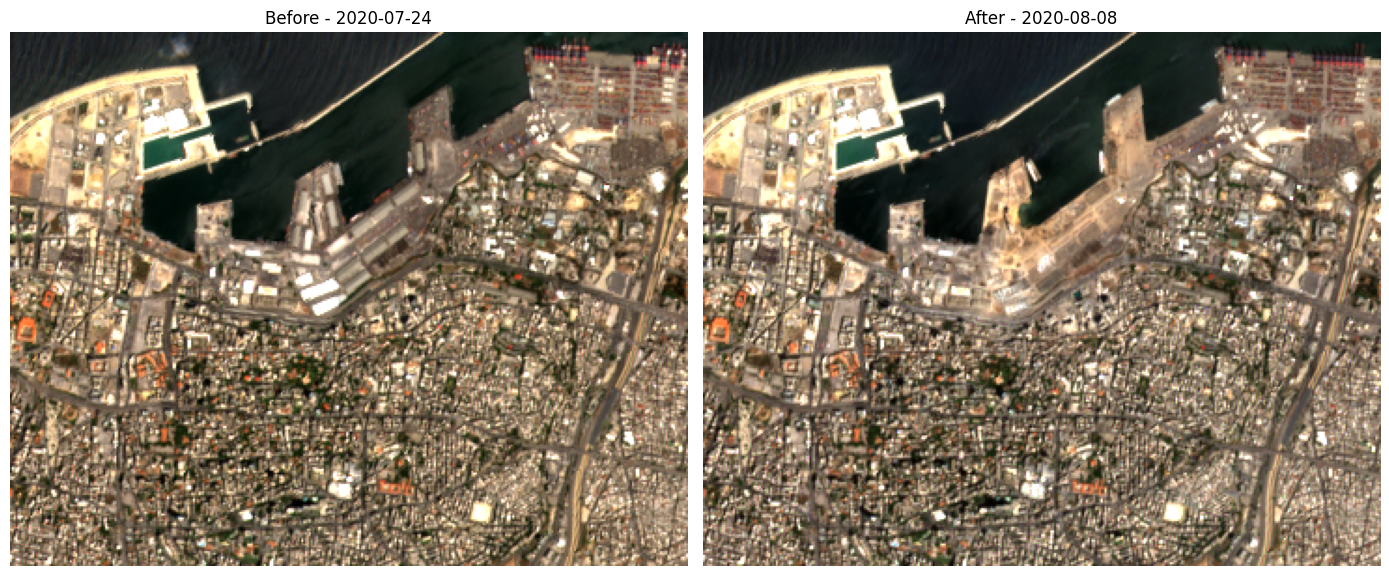

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(true_color_before)
axes[0].set_title(f"Before - {date_before}")
axes[1].imshow(true_color_after)
axes[1].set_title(f"After - {date_after}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Image.fromarray(true_color_before).save("true_color_before.png")
Image.fromarray(true_color_after).save("true_color_after.png")

**Observations:**

- At 10 m, most changes are hard to see by eye.
- On the central piers, the white roofs of the warehouses are gone and replaced by grey and brown rubble.
- The crater is visible: at the base of the central pier, the water now goes further into the quay.

## 5. Building Damage Index (BDI)

### Why not the NDBI alone?

NDBI = (SWIR - NIR) / (SWIR + NIR) (Zha et al., 2003). Tested first: the difference between the two dates is hard to see, because rubble and buildings both have a high SWIR reflectance.

### Four indicators

| Indicator | Formula | What it shows |
|---|---|---|
| NDBI | (B11 - B08) / (B11 + B08) | built-up surfaces |
| BSI (Rikimaru et al., 2002) | ((B11 + B04) - (B08 + B02)) / ((B11 + B04) + (B08 + B02)) | bare soil, rubble |
| Redness | (B04 - B02) / (B04 + B02) | brown colour of dust and rubble |
| Brightness | (B02 + B03 + B04 + B08) / 4 | brightness of the surface |

### Water

Water is removed from the BDI. Water absorbs the infrared, so water = B08 and B11 both below "water_threshold", in large areas only (shadows can look like small water areas). NDWI and MNDWI did not work: the sea is too dark, so the ratio is unstable.

New water (water after the event, not before) is shown apart. Near the explosion, it is the crater.

In [46]:
EPS = 1e-6   # avoids divisions by zero

def nd(a, b):
    return (a - b) / (a + b + EPS)

def compute_indices(b):
    return {
        "NDBI": nd(b["B11"], b["B08"]),
        "BSI": nd(b["B11"] + b["B04"], b["B08"] + b["B02"]),
        "Redness": nd(b["B04"], b["B02"]),
        "Brightness": (b["B02"] + b["B03"] + b["B04"] + b["B08"]) / 4,
    }

def remove_small(mask, min_size):
    # Removes the groups of connected pixels smaller than min_size
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, dtype=bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_size
    return keep[labels]

def water_mask(b):
    water = (b["B08"] < water_threshold) & (b["B11"] < water_threshold)
    water = remove_small(water, 300)   # only large water areas (sea, port basins)
    water = cv2.morphologyEx(water.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))   # fills small holes (waves)
    return water.astype(bool)

def cloud_mask(b):
    return np.isin(np.round(b["SCL"]), CLOUD_CLASSES)

idx_before = compute_indices(before)
idx_after = compute_indices(after)

# Valid pixels: data available, no cloud
valid = (before["dataMask"] > 0) & (after["dataMask"] > 0)
if use_cloud_mask:
    valid = valid & ~cloud_mask(before) & ~cloud_mask(after)

# Land: valid, not water, and not on the quays (1-pixel margin around the water)
water = (water_mask(before) | water_mask(after)).astype(np.uint8)
water = cv2.dilate(water, np.ones((3, 3), np.uint8)).astype(bool)
land = valid & ~water

# New water: water after the event but not before (crater)
new_water = valid & water_mask(after) & ~water_mask(before)
new_water = remove_small(new_water, min_cluster_size)

print(f"Valid pixels: {100 * valid.mean():.1f} %")
print(f"Land pixels used for the BDI: {100 * land.mean():.1f} %")
print(f"New water pixels: {new_water.sum()}")

Valid pixels: 99.3 %
Land pixels used for the BDI: 81.9 %
New water pixels: 548


In [47]:
# Check of the water threshold: reflectance of the sea and of the city
sea = (slice(0, 10), slice(0, 120))    # top-left corner: open sea
city = (slice(200, None), slice(None))     # bottom of the image: city

for label, b in [("BEFORE", before), ("AFTER", after)]:
    print(label)
    for zone_name, zone in [("sea", sea), ("city", city)]:
        for band in ["B08", "B11"]:
            p = np.percentile(b[band][zone], [5, 50, 95])
            print(f"   {zone_name:5s} {band}   5%: {p[0]:.3f}   median: {p[1]:.3f}   95%: {p[2]:.3f}")

BEFORE
   sea   B08   5%: 0.033   median: 0.043   95%: 0.083
   sea   B11   5%: 0.044   median: 0.052   95%: 0.071
   city  B08   5%: 0.129   median: 0.231   95%: 0.357
   city  B11   5%: 0.183   median: 0.248   95%: 0.329
AFTER
   sea   B08   5%: 0.025   median: 0.032   95%: 0.041
   sea   B11   5%: 0.037   median: 0.041   95%: 0.046
   city  B08   5%: 0.125   median: 0.223   95%: 0.342
   city  B11   5%: 0.172   median: 0.237   95%: 0.316


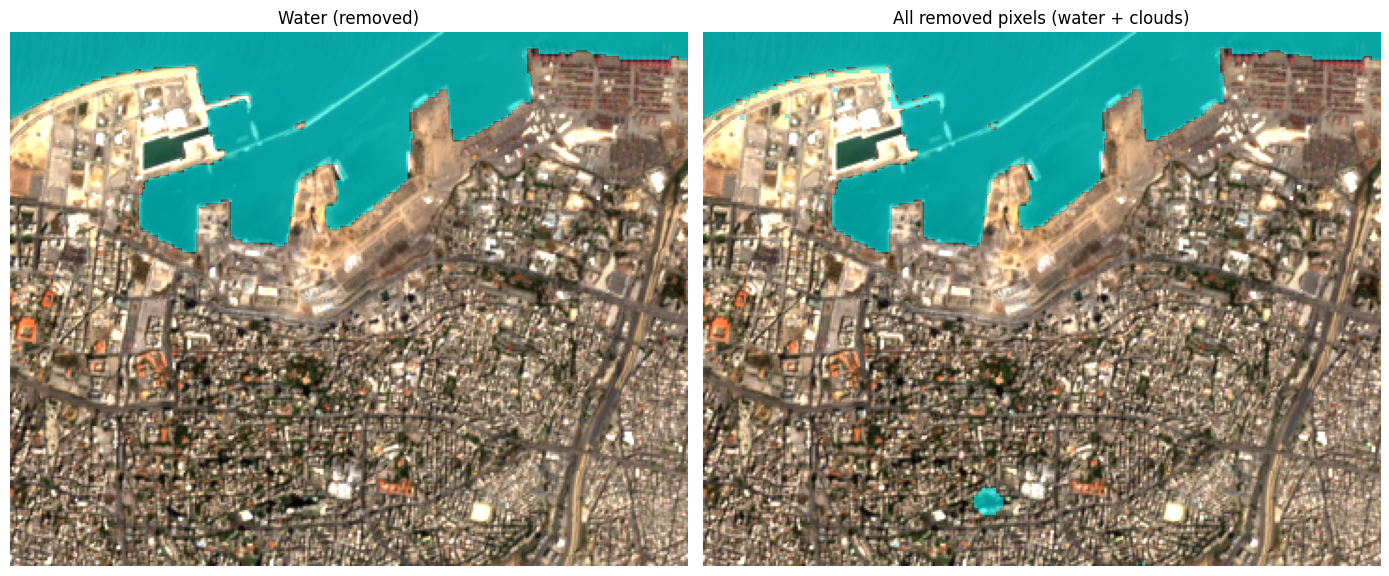

In [48]:
# Check of the masks
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(true_color_after)
axes[0].imshow(np.where(water, 1, np.nan), cmap="cool", alpha=0.6)
axes[0].set_title("Water (removed)")
axes[1].imshow(true_color_after)
axes[1].imshow(np.where(~land, 1, np.nan), cmap="cool", alpha=0.6)
axes[1].set_title("All removed pixels (water + clouds)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [49]:
FEATURES = ["NDBI", "BSI", "Redness", "Brightness"]

def robust_z(diff, mask):
    median = np.median(diff[mask])
    mad = 1.4826 * np.median(np.abs(diff[mask] - median))
    return (diff - median) / (mad + EPS)

z = {}
for name in FEATURES:
    diff = idx_after[name] - idx_before[name]
    diff = cv2.blur(diff, (smoothing_window, smoothing_window))
    z[name] = robust_z(diff, land)

bdi = np.sqrt(np.mean([z[name] ** 2 for name in FEATURES], axis=0))
bdi[~land] = np.nan

print(f"BDI median: {np.nanmedian(bdi):.2f}")
print(f"BDI 99th percentile: {np.nanpercentile(bdi, 99):.2f}")

BDI median: 0.86
BDI 99th percentile: 6.95


### NDBI difference vs BDI

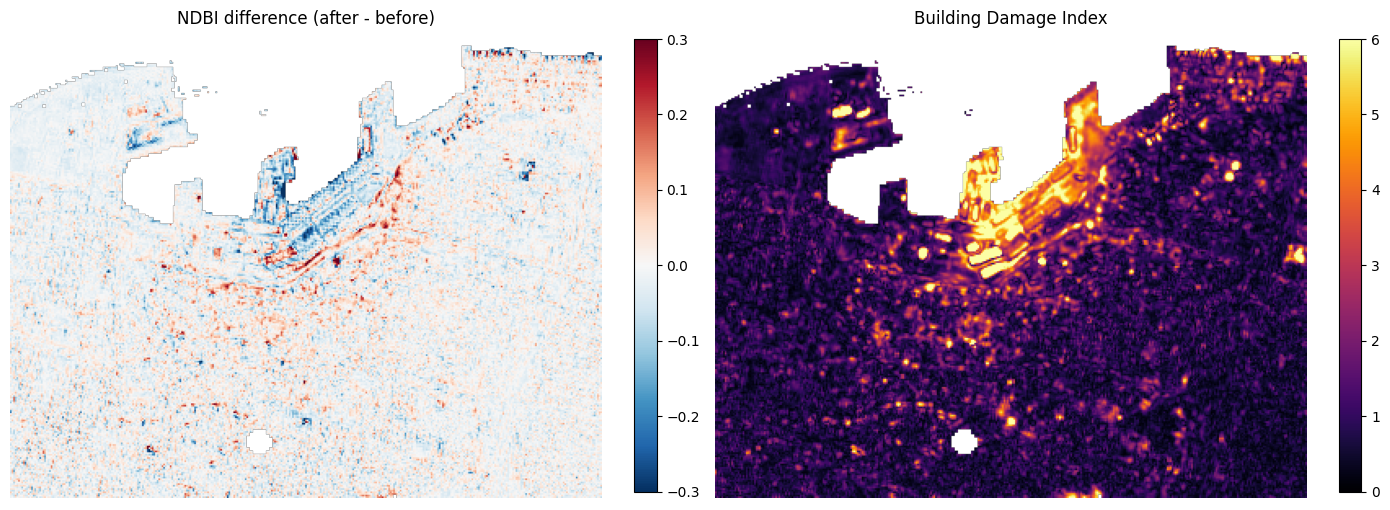

In [50]:
ndbi_diff = np.where(land, idx_after["NDBI"] - idx_before["NDBI"], np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(ndbi_diff, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
axes[0].set_title("NDBI difference (after - before)")
plt.colorbar(im0, ax=axes[0], fraction=0.035)
im1 = axes[1].imshow(bdi, cmap="inferno", vmin=0, vmax=6)
axes[1].set_title("Building Damage Index")
plt.colorbar(im1, ax=axes[1], fraction=0.035)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("ndbi_vs_bdi.png", dpi=150)
plt.show()

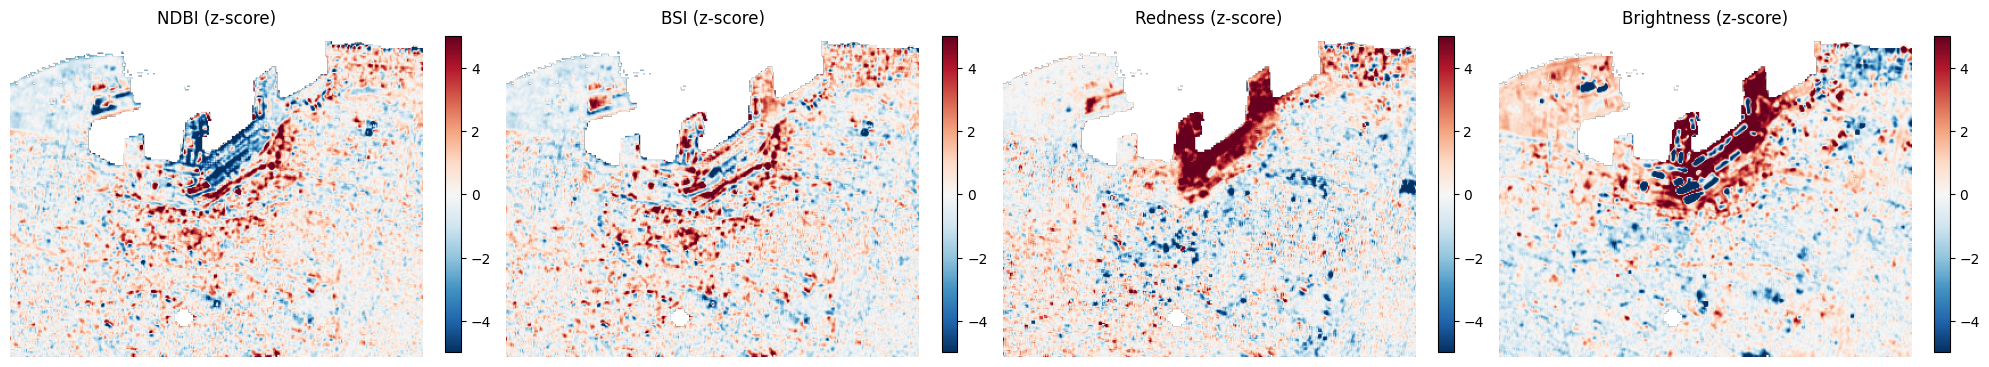

In [51]:
#contribution of each indicator
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, name in zip(axes, FEATURES):
    im = ax.imshow(np.where(land, z[name], np.nan), cmap="RdBu_r", vmin=-5, vmax=5)
    ax.set_title(f"{name} (z-score)")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.035)
plt.tight_layout()
plt.savefig("bdi_components.png", dpi=150)
plt.show()

**Observations:**

- Water mask: on the sea, B08 and B11 stay below 0.09, and in the city they are above 0.12. A threshold of 0.1 separates them well. NDWI and MNDWI did not work here because the sea is too dark, so the ratio is unstable.
- The NDBI difference is mostly noise. Some changes appear on the piers, but the damaged area does not stand out.
- The BDI shows the port very clearly (values above 6), while most of the city stays low (median 0.86).
- Redness gives the strongest signal: it increases a lot on the piers, where grey roofs became brown rubble and dust.
- Brightness: the bright warehouse roofs became darker, and the area around became brighter because of the dust.
- The white disk in the south is a small cloud removed by the cloud mask.

## 6. Damage map

Same method as the end of the first part of the Lab, on the true color image after the event:

| Class | Rule | Colour |
|---|---|---|
| No visible change | BDI < `threshold_moderate` | true color |
| Moderate | between the two thresholds | orange |
| Severe | BDI >= `threshold_severe` | red |

Groups smaller than `min_cluster_size` pixels are removed (isolated pixels are mostly noise: shadows, cars).

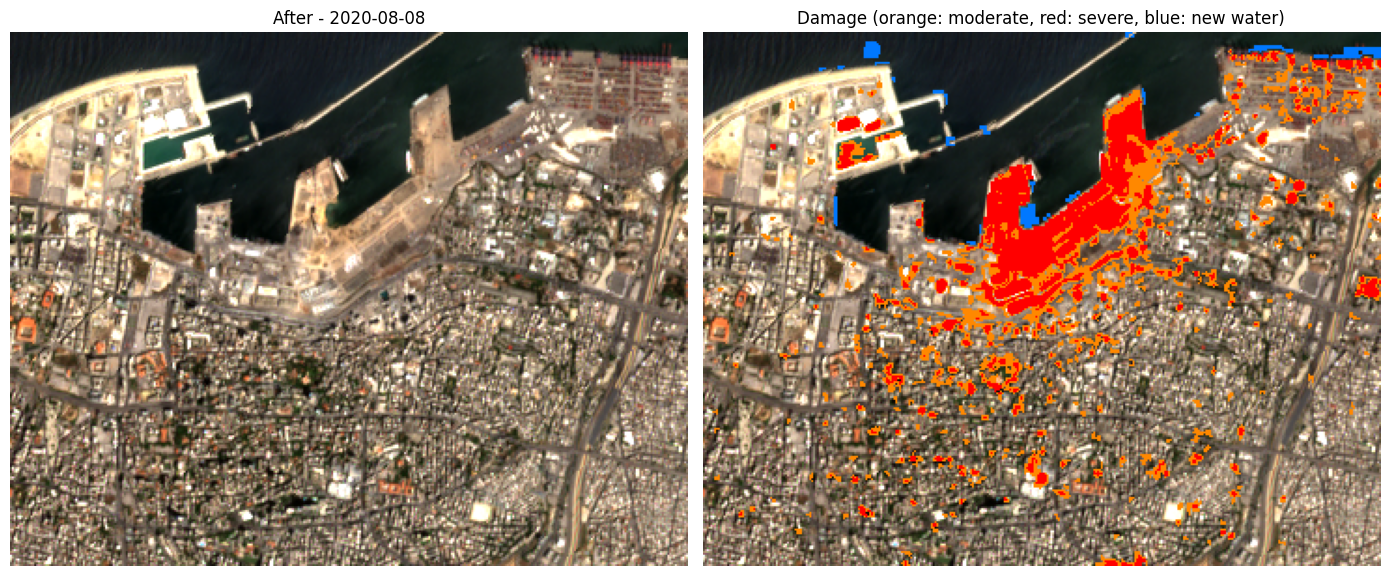

In [53]:
damaged = remove_small(land & (bdi >= threshold_moderate), min_cluster_size)
moderate = damaged & (bdi < threshold_severe)
severe = damaged & (bdi >= threshold_severe)

composite = np.array(true_color_after)
composite[moderate] = [255, 136, 0]
composite[severe] = [255, 0, 0]
composite[new_water] = [0, 120, 255]

# Same classes on a transparent background, for the folium map
overlay = np.zeros((*bdi.shape, 4), dtype=np.uint8)
overlay[moderate] = [255, 136, 0, 200]
overlay[severe] = [255, 0, 0, 200]
overlay[new_water] = [0, 120, 255, 200]

Image.fromarray(composite).save("damage_composite.png")
Image.fromarray(overlay).save("damage_overlay.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(true_color_after)
axes[0].set_title(f"After - {date_after}")
axes[1].imshow(composite)
axes[1].set_title("Damage (orange: moderate, red: severe, blue: new water)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observations:**

- Severe changes (red) cover the central piers, where the warehouses and the grain silos were.
- Moderate changes (orange) spread into the districts south and east of the port.
- New water (blue) appears at the base of the central pier: this is the crater.
- Some changes are not caused by the explosion: moved containers in the container terminal (top right), ships that left the port (blue along the quays), and small spots in the city (shadows, cars).

## 7. Damaged area and distance analysis

One pixel = 10 x 10 m = 0.01 ha.

If the BDI really shows the damage of the explosion, the share of damaged pixels should decrease with the distance to the explosion.

In [57]:
# Distance (m) from each pixel to the explosion point
h, w = bdi.shape
lon_min, lat_min, lon_max, lat_max = aoi_bbox
lats = lat_max - (np.arange(h) + 0.5) * (lat_max - lat_min) / h
lons = lon_min + (np.arange(w) + 0.5) * (lon_max - lon_min) / w
lon_grid, lat_grid = np.meshgrid(lons, lats)

lat0, lon0 = event_point
dy = (lat_grid - lat0) * 111_320                                  # 1 degree of latitude = 111.32 km
dx = (lon_grid - lon0) * 111_320 * np.cos(np.radians(lat0))       # shorter for longitude
distance = np.sqrt(dx ** 2 + dy ** 2)

# The crater can only be near the explosion point. Other new water = ships that left the port.
crater = new_water & (distance < crater_radius)

pixel_area_ha = resolution ** 2 / 10_000
print(f"Moderate:  {moderate.sum():6d} pixels = {moderate.sum() * pixel_area_ha:6.1f} ha")
print(f"Severe:    {severe.sum():6d} pixels = {severe.sum() * pixel_area_ha:6.1f} ha")
print(f"Total:     {damaged.sum():6d} pixels = {damaged.sum() * pixel_area_ha:6.1f} ha")
print(f"New water: {new_water.sum():6d} pixels = {new_water.sum() * pixel_area_ha:6.1f} ha")
print(f"Crater (< {crater_radius} m from the explosion): {crater.sum()} pixels = {crater.sum() * pixel_area_ha:.2f} ha")

Moderate:    6621 pixels =   66.2 ha
Severe:      5471 pixels =   54.7 ha
Total:      12092 pixels =  120.9 ha
New water:    548 pixels =    5.5 ha
Crater (< 300 m from the explosion): 136 pixels = 1.36 ha


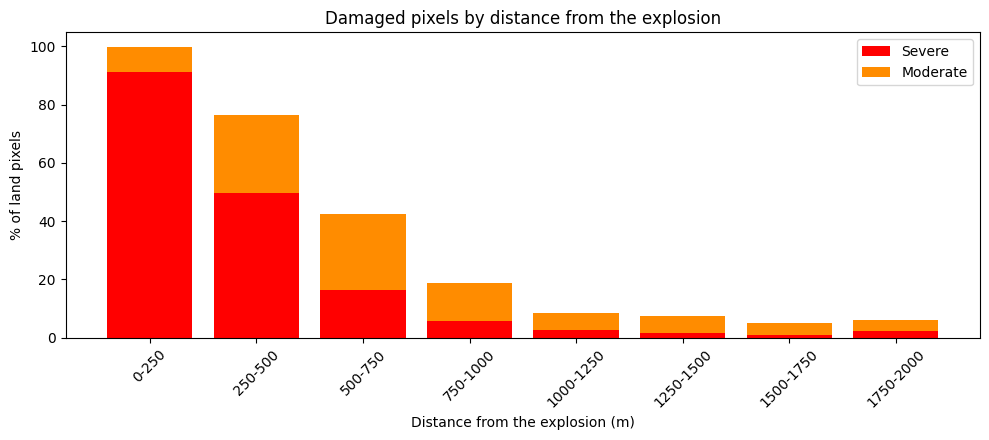

In [58]:
#used as a verification of the BDI methodology
# Share of damaged land pixels in each ring around the explosion
rings = np.arange(0, ring_max + ring_step, ring_step)
labels, pct_moderate, pct_severe = [], [], []
for r_in, r_out in zip(rings[:-1], rings[1:]):
    ring = land & (distance >= r_in) & (distance < r_out)
    n = max(ring.sum(), 1)
    labels.append(f"{r_in}-{r_out}")
    pct_moderate.append(100 * (moderate & ring).sum() / n)
    pct_severe.append(100 * (severe & ring).sum() / n)

x = np.arange(len(labels))
plt.figure(figsize=(10, 4.5))
plt.bar(x, pct_severe, color="red", label="Severe")
plt.bar(x, pct_moderate, bottom=pct_severe, color="darkorange", label="Moderate")
plt.xticks(x, labels, rotation=45)
plt.xlabel("Distance from the explosion (m)")
plt.ylabel("% of land pixels")
plt.title("Damaged pixels by distance from the explosion")
plt.legend()
plt.tight_layout()
plt.savefig("damage_by_distance.png", dpi=150)
plt.show()

**Observations:**

- Changed area: 120.9 ha (54.7 ha severe, 66.2 ha moderate). This is a maximum, because it also includes some false detections.
- Crater: 1.36 ha (136 pixels). Satellite analyses give a crater of about 150 m wide, so our estimate is close, a bit smaller because of the mixed pixels on the edges. The rest of the new water (about 4 ha) comes from ships that left the port.
- The share of damaged pixels goes down with the distance: 100 % below 250 m, 76 % between 250 and 500 m, 42 % between 500 and 750 m, and 19 % between 750 and 1000 m.
- After 1 km, it stays around 5 to 8 %. This is the background noise of the method.
- So Sentinel-2 can detect the damage up to about 1 km. Further away, the damage (windows, facades) is too small to be seen at 10 m.

## 8. Folium map


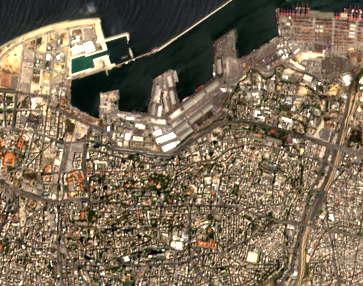
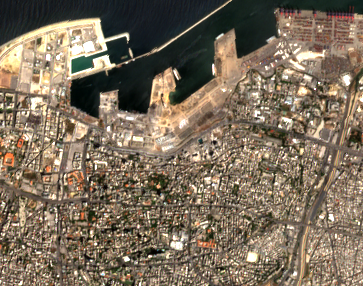
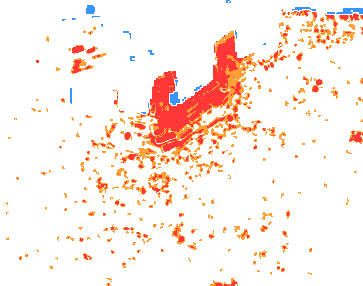

In [59]:
bounds = [(lat_min, lon_min), (lat_max, lon_max)]

m = folium.Map(location=event_point, zoom_start=15, tiles="OpenStreetMap")
folium.raster_layers.ImageOverlay("true_color_before.png", bounds=bounds, name=f"Before ({date_before})", show=False).add_to(m)
folium.raster_layers.ImageOverlay("true_color_after.png", bounds=bounds, name=f"After ({date_after})", show=False).add_to(m)
folium.raster_layers.ImageOverlay("damage_overlay.png", bounds=bounds, name="Damage").add_to(m)

folium.GeoJson(shapely.geometry.box(*aoi_bbox), name="Area of interest",
               style_function=lambda x: {"color": "blue", "fill": False}).add_to(m)
for r in rings[1:]:
    folium.Circle(event_point, radius=int(r), color="black", weight=1, fill=False).add_to(m)
folium.Marker(event_point, tooltip=event_name, icon=folium.Icon(color="red")).add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds(bounds)
m.save("damage_map.html")
display(m)

## 9. Limitations and improvements

**Limitations**
- Resolution: one pixel is 10 x 10 m (20 m for B11), so small damage like broken windows cannot be seen.
- We only see the roofs. A building can be destroyed inside and still have an intact roof.
- Port activity: containers and ships move between two dates and are detected as changes.
- Clouds: the closest date before the explosion was cloudy, so the two images are 15 days apart.
- The thresholds are statistical. They are not calibrated with truth.

**Possible improvements**
- Compare the map with an official damage map (UNOSAT, NASA) to check and adjust the thresholds.
- Add Sentinel-1 radar images, which work through clouds and react to the shape of buildings.
- Use several dates before and after the event to remove the normal changes of the port.

**Event references**
- The Guardian (5 August 2020). Visual guide: how the explosion caused mass casualties and devastation across Beirut.
- NASA Earth Observatory (11 August 2020). Scientists Map Beirut Blast Damage.
- UNFPA Lebanon (12 August 2020). Flash Appeal: 2020 Beirut Explosion.